# Adım 2b · Gradient boosting (HistGradientBoostingRegressor)

*2. adımın ikinci yarısı; 2a linear regression `02a-linreg.ipynb`'de.*

2a'da LinearRegression'la 4,41 → **2,90**'a indik. Ama her kazancı biz elle bulduk: u/v, hamle, yaz×saat, kuzeyli bayrağı. LR yalnız "katsayı × feature" toplayabildiği için doğrusal olmayan her şeyi ona biz hazırlamak zorundaydık.

**Karar ağacı** başka türlü çalışır: veriyi sorularla böler. Örneğin "gfs > 8 mi? → evet → yön 300–60° arası mı? → evet → tahmin 14 kn". Her yaprak kendi ortalamasını tahmin eder. Böylece "kuzeyliyse ve yazsa ve öğleden sonraysa" gibi etkileşimleri kendisi bulur; çarpım sütunu yazmamıza gerek kalmaz.

Tek bir ağaç ya kaba kalır ya ezberler. **Gradient boosting** bu yüzden çok sayıda *küçük* ağacı sırayla kurar:
1. İlk tahmin: herkese ortalama.
2. Her satırın hatasını (gerçek − tahmin) hesapla.
3. Yeni küçük bir ağaç **bu hatayı** tahmin etmeyi öğrenir; tahmine onun küçük bir kısmı (`learning_rate`, varsayılan 0,1) eklenir.
4. 2–3'ü `max_iter` kez tekrarla.

Her ağaç öncekilerin kaçırdığını biraz düzeltir. "Hist" kısmı hız hilesi: her sayısal sütunu en çok 255 kutuya bölüp bölme noktası olarak yalnız kutu sınırlarını dener (LightGBM'in fikri).

**Neden sklearn'ün HistGB'si (Cengo seçti):** kurulu, LR'yle aynı `fit`/`predict` arayüzü, bizim 23 bin satırda saniyenin altında eğitiliyor.

In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

from ruzgar.data import load_aligned, split

aligned = load_aligned()
train, test = split(aligned)
y_train, y_test = train["speed_kn_obs"], test["speed_kn_obs"]
MAE_LR = 2.90  # 02a-linreg'in en iyisi (hamle + yaz×saat + kuzeyli)
len(train), len(test)

(14629, 8804)

## 1. Ham feature'larla boosting

Ağaç için sin/cos'a gerek yok. LR'de saati sin/cos'a çevirmiştik çünkü LR için 23 ile 0 çok uzak sayılardı. Ağaç ise "saat 9–17 arası mı?" diye doğrudan bölebilir; sırayı ve aralıkları kendisi bulur. Yön için de aynı: u/v yerine ham dereceyi veriyoruz.

Yani modele yalnız GFS'in ham çıktıları ve zaman veriliyor, hiçbir elle feature yok. Soru: bizim 2a'da elle bulduklarımızı kendisi bulabilecek mi?

`early_stopping=False`: sklearn varsayılan olarak veriden **rastgele** %10 ayırıp erken durmaya karar verebilir. Zaman serisinde rastgele bölme leakage yaratır (yarının verisiyle bugün karar verilir), o yüzden kapatıyoruz; durma noktasını aşağıda kendimiz, zaman bölmesiyle seçeceğiz. `random_state=0` aynı sonucu tekrar almak için.

In [2]:
def ham_ozellikler(df):
    X = pd.DataFrame(index=df.index)
    X["gfs"] = df["speed_kn_gfs"]
    X["yon"] = df["dir_deg_gfs"]
    X["hamle_gfs"] = df["gust_kn_gfs"]
    X["saat"] = df["time"].dt.hour
    X["ay"] = df["time"].dt.month
    return X

model = HistGradientBoostingRegressor(max_iter=100, early_stopping=False, random_state=0)
model.fit(ham_ozellikler(train), y_train)

mae_train = mean_absolute_error(y_train, model.predict(ham_ozellikler(train)))
mae_gb = mean_absolute_error(y_test, model.predict(ham_ozellikler(test)))
print(f"Train MAE: {mae_train:.2f}   Test MAE: {mae_gb:.2f}   (LR en iyi: {MAE_LR:.2f})")

Train MAE: 2.08   Test MAE: 2.42   (LR en iyi: 2.90)


Pezo'nun ölçümü: test **~2,42**. Hiç elle feature vermeden LR'nin en iyisinden ~0,5 kn daha iyi.

**Train ile test farkına da bak:** train 2,08, test 2,42. Model gördüğü veride daha iyi; bu normal, ama fark büyürse **overfitting** (ezber) var demektir. 3. bölümde bunu bilerek bozacağız.

## 2. Elle feature'ları da verirsek?

02'deki bütün feature'ları (u/v, hamle, yaz×saat, kuzeyli) aynı modele verelim. Ağaç etkileşimleri kendi buluyorsa kazanç az olmalı.

In [3]:
def el_ozellikler(df):
    # 02a-linreg'in son hali (ozellikler_kuzey), tek fonksiyonda
    saat = df["time"].dt.hour
    ay = df["time"].dt.month
    yon = np.deg2rad(df["dir_deg_gfs"])
    X = pd.DataFrame(index=df.index)
    X["gfs"] = df["speed_kn_gfs"]
    X["saat_sin"] = np.sin(2 * np.pi * saat / 24)
    X["saat_cos"] = np.cos(2 * np.pi * saat / 24)
    X["ay_sin"] = np.sin(2 * np.pi * ay / 12)
    X["ay_cos"] = np.cos(2 * np.pi * ay / 12)
    X["u_ruzgar"] = df["speed_kn_gfs"] * np.sin(yon)
    X["v_ruzgar"] = df["speed_kn_gfs"] * np.cos(yon)
    X["hamle_gfs"] = df["gust_kn_gfs"]
    yaz = ay.isin([6, 7, 8, 9]).astype(int)
    X["yaz"] = yaz
    X["yaz_saat_sin"] = yaz * X["saat_sin"]
    X["yaz_saat_cos"] = yaz * X["saat_cos"]
    X["kuzeyli"] = (X["v_ruzgar"] > 0).astype(int)
    X["kuzeyli_hiz"] = X["kuzeyli"] * df["speed_kn_gfs"]
    return X

model_el = HistGradientBoostingRegressor(max_iter=100, early_stopping=False, random_state=0)
model_el.fit(el_ozellikler(train), y_train)
mae_gb_el = mean_absolute_error(y_test, model_el.predict(el_ozellikler(test)))
print(f"Test MAE: {mae_gb_el:.2f}   (ham feature'larla: {mae_gb:.2f})")

Test MAE: 2.41   (ham feature'larla: 2.42)


Pezo'nun ölçümü: **~2,41**, ham feature'larla neredeyse aynı. Ağaç, bizim 2a'da tek tek elle kurduğumuz etkileşimleri kendisi bulmuş. Bu boosting'in asıl gücü; LR'de feature mühendisliği zorunluydu, burada çoğu zaman gerekmiyor.

(Bu, 2a'nın boşa gittiği anlamına gelmiyor: hangi bilginin işe yaradığını orada öğrendik. Kuzeyli hata, imbat, hamle: bunlar modelden bağımsız olarak verinin hikâyesi.)

## 3. Overfitting: ağaç sayısını abartınca

`max_iter` = kaç ağaç kurulacağı. Az ağaç → model kaba kalır (underfitting). Çok ağaç → her yeni ağaç artık gerçek deseni değil train'deki gürültüyü düzeltmeye başlar: train hatası düşmeye devam eder ama yeni veride kötüleşir (overfitting).

Ama bunu **test** üzerinde ayarlarsak test'i kirletiriz: en iyi `max_iter`'i testle seçersek test artık "hiç görülmemiş veri" olmaz, skorumuz iyimser çıkar. Doğrusu train'in içinden bir **validation** dilimi ayırmak. Zaman serisi olduğu için yine zamanla: train'in son 3 ayı (Ağustos–Ekim 2025) validation.

Yeni kalıp: zaten yazdığımız `split` fonksiyonu kesim tarihi alıyor; train'e tekrar uygulayınca train'i ikiye bölüyor.

In [4]:
train2, val = split(train, pd.Timestamp("2025-08-01", tz="UTC"))
print(len(train2), "train2 satır,", len(val), "validation satır")

12423 train2 satır, 2206 validation satır


## 4. Alıştırma (iskelet: sen yazıyorsun)

Farklı `max_iter` değerleri için modeli **train2**'de eğit, hem train2 hem **val** MAE'sini ölç, tabloya koy.

Kalıp hatırlatma:
- `for n in [25, 50, 100]:` listedeki her değer için içerideki girintili satırları çalıştırır.
- Sonuçları bir listeye sözlük olarak biriktirip sonunda tabloya çevirmek: `sonuclar.append({"max_iter": n, "train": ..., "val": ...})` → döngü bitince `pd.DataFrame(sonuclar)`.

In [5]:
sonuclar = []
for n in [25, 50, 100, 200, 500, 1000]:
    # 1) max_iter=n olan bir HistGradientBoostingRegressor kur (early_stopping=False, random_state=0)
    #    ve ham_ozellikler(train2) ile train2["speed_kn_obs"] üzerinde fit et
    model = HistGradientBoostingRegressor(max_iter=n, early_stopping=False, random_state=0)
    model.fit(ham_ozellikler(train2), train2["speed_kn_obs"])

    # 2) train2 üzerindeki MAE'yi hesapla
    mae_train2 = mean_absolute_error(train2["speed_kn_obs"], model.predict(ham_ozellikler(train2)))
    # 3) val üzerindeki MAE'yi hesapla
    mae_val = mean_absolute_error(val["speed_kn_obs"], model.predict(ham_ozellikler(val)))
    # 4) sonuclar listesine {"max_iter": n, "train": ..., "val": ...} ekle
    sonuclar.append({"max_iter": n, "train": mae_train2, "val": mae_val})
pd.DataFrame(sonuclar).round(3)

,max_iter,train,val
0,25,2.321,2.425
1,50,2.161,2.338
2,100,2.057,2.347
3,200,1.911,2.350
4,500,1.643,2.424
5,1000,1.364,2.487


### Aynı şey grafikle: her ağaç sayısı için (Pezo yazdı)

Tablodaki 6 nokta yerine 1'den 1000'e her ağaç sayısı. `staged_predict` tek modeli ağaç ağaç oynatır: her ağaç eklendikten sonraki tahmini sırayla verir, 1000 ayrı model eğitmek gerekmez.

Yeni kalıp, list comprehension: `[ifade for t in ...]` = `for` + `append` ile liste doldurmanın tek satırlık hali.

Okuma (Pezo ölçümü): val ~30 ağaca kadar hızla düşer, 30–200 arası neredeyse düz, sonra yükselir. En düşük nokta 63 ağaç (2,329); 125 bu düz dibin içinde, fark 0,01 kn'dan az. Train hep düşer; iki eğri arası açıklık = overfitting.

en düşük val: 63 ağaç, 2.329


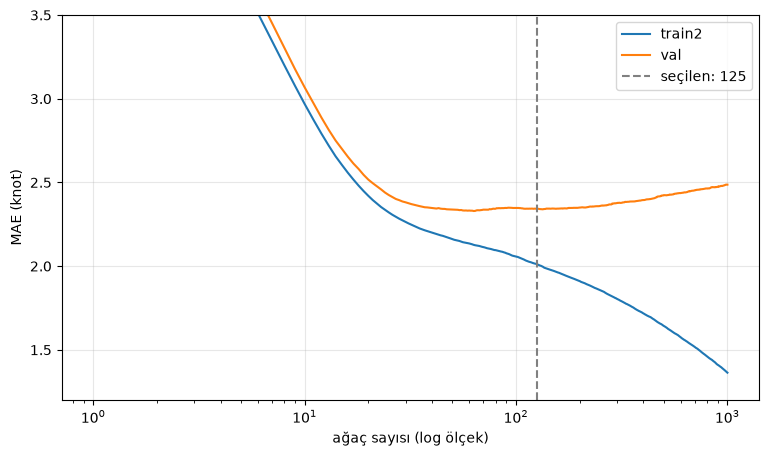

In [6]:
import matplotlib.pyplot as plt

model = HistGradientBoostingRegressor(max_iter=1000, early_stopping=False, random_state=0)
model.fit(ham_ozellikler(train2), train2["speed_kn_obs"])

egri_train = [mean_absolute_error(train2["speed_kn_obs"], t) for t in model.staged_predict(ham_ozellikler(train2))]
egri_val = [mean_absolute_error(val["speed_kn_obs"], t) for t in model.staged_predict(ham_ozellikler(val))]
agac = range(1, len(egri_train) + 1)
print("en düşük val:", int(np.argmin(egri_val)) + 1, "ağaç,", round(min(egri_val), 3))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(agac, egri_train, label="train2")
ax.plot(agac, egri_val, label="val")
ax.axvline(125, color="gray", linestyle="--", label="seçilen: 125")
ax.set_xscale("log")          # 1–10 ile 100–1000 aynı genişlikte görünsün
ax.set_ylim(1.2, 3.5)
ax.set_xlabel("ağaç sayısı (log ölçek)")
ax.set_ylabel("MAE (knot)")
ax.legend()
ax.grid(alpha=0.3)

**Okurken sor:** train MAE hep düşüyor mu? Val MAE nerede en düşük, sonra ne oluyor? En iyi `max_iter` sence hangisi?

Seçtiğin değerle modeli **bütün train**'de (train2 + val) yeniden eğitip testte **bir kez** ölçeceğiz; o sayı özet tablosuna girer.

## 5. Son ölçüm: testte bir kez (iskelet: sen yazıyorsun)

**Cengo'nun seçimi: `max_iter=125`.** Val 50–200 arasında düz (fark ~0,01 kn, gürültü düzeyinde), 125 bu düz dibin ortası; iki yandan da güvenli.

Şimdi bu değerle modeli **bütün train**'de (train2 + val, yani `train`) yeniden eğitip **test**'te ölçüyoruz. Neden tekrar eğitiyoruz: val'i yalnız ayar seçmek için ayırmıştık; ayar seçildi, artık o 3 ay da eğitime girebilir, model daha fazla veri görür.

Test'e yalnız bir kez bakılır. Bu sayıyı görüp `max_iter`'i değiştirirsek test de validation'a dönüşür ve skor iyimser olur.

Kalıp: 1. bölümdeki hücreyle aynı, yalnız `max_iter` farklı.

In [7]:
# 1) max_iter=125 olan modeli kur (early_stopping=False, random_state=0) ve ham_ozellikler(train), y_train ile fit et
model = HistGradientBoostingRegressor(max_iter=125, early_stopping=False, random_state=0)
model.fit(ham_ozellikler(train), train["speed_kn_obs"])
# 2) test üzerindeki MAE'yi hesapla, mae_final değişkenine ata
mae_final = mean_absolute_error(test["speed_kn_obs"], model.predict(ham_ozellikler(test)))
print(f"Test MAE: {mae_final:.2f}   (LR en iyi: {MAE_LR:.2f})")

Test MAE: 2.42   (LR en iyi: 2.90)


## 2. adımın özeti

Bu hücre hazır: çalıştır.

In [8]:
pd.DataFrame({
    "yöntem": [
        "ham GFS",
        "sabit düzeltme",
        "aylık düzeltme",
        "LR: gfs",
        "LR: + saat, ay, yön (u/v)",
        "LR: + hamle",
        "LR: + yaz×saat",
        "LR: + kuzeyli",
        "HistGB: ham feature, 125 ağaç",
    ],
    "test MAE": [4.41, 3.80, 3.65, 3.77, 3.14, 3.03, 2.97, MAE_LR, mae_final],
}).round(2)

,yöntem,test MAE
0,ham GFS,4.41
1,sabit düzeltme,3.80
2,aylık düzeltme,3.65
3,LR: gfs,3.77
4,"LR: + saat, ay, yön (u/v)",3.14
5,LR: + hamle,3.03
6,LR: + yaz×saat,2.97
7,LR: + kuzeyli,2.90
8,"HistGB: ham feature, 125 ağaç",2.42
